# Probes

Trains the Nom/Acc probes on the features cached by `data.ipynb`. Everything
here is scored on the Marathi dev split; the test split stays untouched until
the pipeline is fixed.

In [1]:
import json
from pathlib import Path

import numpy as np
import yaml
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd()
CONFIG = yaml.safe_load((ROOT / "config.yaml").read_text())
CACHE = ROOT / "data" / "cache"
samples = json.loads((CACHE / "samples.json").read_text())


def load(language: str, split: str, layer: int, pooling: str, sentences: set[int] | None = None):
    """Return the cached features and labels at one layer, optionally only for some sentences."""
    nouns = json.loads((CACHE / f"{language}_{split}_nouns.json").read_text())
    keep = [k for k, noun in enumerate(nouns) if sentences is None or noun["sentence"] in sentences]
    x = np.load(CACHE / f"{language}_{split}_{pooling}.npy", mmap_mode="r")[layer]
    return np.asarray(x[keep]), np.array([nouns[k]["label"] for k in keep])


def fit(x: np.ndarray, y: np.ndarray) -> LogisticRegression:
    return LogisticRegression(max_iter=5000).fit(x, y)


def cosine(a: LogisticRegression, b: LogisticRegression) -> float:
    u, v = a.coef_[0], b.coef_[0]
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))

## Reproducing the class result

Layer 8, first-piece pooling. The Hindi probe is trained on the seed's 800 Hindi
sentences and the Marathi probe on its first 800 Marathi sentences. The
Hindi-halves cosine compares probes trained on the two halves of the Hindi
sample. Class numbers: Hindi→Marathi 80%, Marathi→Marathi 86%, cosine 0.21,
Hindi halves 0.44–0.51.

In [2]:
layer, pooling = CONFIG["reproduction"]["layer"], CONFIG["reproduction"]["pooling"]
n = CONFIG["hindi_train_sentences"]
x_dev, y_dev = load("mr", "dev", layer, pooling)

runs = []
for seed in map(str, CONFIG["seeds"]):
    hindi = samples["hi"][seed]
    hindi_probe = fit(*load("hi", "train", layer, pooling, set(hindi)))
    marathi_probe = fit(*load("mr", "train", layer, pooling, set(samples["mr"][seed][:n])))
    half_a = fit(*load("hi", "train", layer, pooling, set(hindi[:n // 2])))
    half_b = fit(*load("hi", "train", layer, pooling, set(hindi[n // 2:])))
    runs.append({
        "seed": int(seed),
        "hindi_on_marathi": hindi_probe.score(x_dev, y_dev),
        "marathi_on_marathi": marathi_probe.score(x_dev, y_dev),
        "cosine_hindi_marathi": cosine(hindi_probe, marathi_probe),
        "cosine_hindi_halves": cosine(half_a, half_b),
    })

summary = {key: {"mean": np.mean([run[key] for run in runs]), "std": np.std([run[key] for run in runs])}
           for key in runs[0] if key != "seed"}
majority = max(np.mean(y_dev == label) for label in CONFIG["labels"])
result = {"layer": layer, "pooling": pooling, "split": "mr dev", "majority": majority,
          "summary": summary, "runs": runs}
(ROOT / "results" / "reproduction.json").write_text(json.dumps(result, indent=2) + "\n")

print(f"Marathi dev majority: {majority:.3f}")
for key, value in summary.items():
    print(f"{key:22s} {value['mean']:.3f} ± {value['std']:.3f}   per seed:",
          " ".join(f"{run[key]:.3f}" for run in runs))

Marathi dev majority: 0.516
hindi_on_marathi       0.833 ± 0.007   per seed: 0.831 0.840 0.820 0.838 0.835
marathi_on_marathi     0.863 ± 0.005   per seed: 0.861 0.867 0.863 0.870 0.855
cosine_hindi_marathi   0.267 ± 0.015   per seed: 0.262 0.291 0.278 0.256 0.250
cosine_hindi_halves    0.459 ± 0.009   per seed: 0.472 0.458 0.465 0.451 0.448


## Headroom

For every layer and pooling, trains the Hindi and Marathi probes as above and
scores both on Marathi dev. A combination can only beat the Marathi probe on
nouns where the two probes disagree. The oracle router picks whichever probe is
right on each noun, so its accuracy is the ceiling for a router that chooses
between the two (and for any convex mix of their logits, since a mix can only
be right where one of them is). `only_hindi_right` is the share of nouns that
the Hindi probe gets right and the Marathi probe gets wrong: the most a
combination can gain.

Two probes trained on different data disagree on some nouns even when neither
knows anything the other doesn't, so the same numbers are computed for a second
Marathi probe trained on the next 800 sentences of the seed's order (disjoint
from the first). Hindi adds something only if its headroom over the Marathi
probe is larger than this Marathi+Marathi headroom.

first layer 0 done
first layer 1 done
first layer 2 done
first layer 3 done
first layer 4 done
first layer 5 done
first layer 6 done
first layer 7 done
first layer 8 done
first layer 9 done
first layer 10 done
first layer 11 done
first layer 12 done
last layer 0 done
last layer 1 done
last layer 2 done
last layer 3 done
last layer 4 done
last layer 5 done
last layer 6 done
last layer 7 done
last layer 8 done
last layer 9 done
last layer 10 done
last layer 11 done
last layer 12 done

Hindi + Marathi
pooling  layer                 hindi               marathi              disagree      only_hindi_right                oracle                cosine
first        0          0.526 ± 0.016          0.603 ± 0.006          0.447 ± 0.025          0.185 ± 0.014          0.788 ± 0.010         -0.044 ± 0.039
first        1          0.558 ± 0.015          0.666 ± 0.007          0.438 ± 0.019          0.165 ± 0.006          0.831 ± 0.004          0.069 ± 0.035
first        2          0.599 ± 0.005      

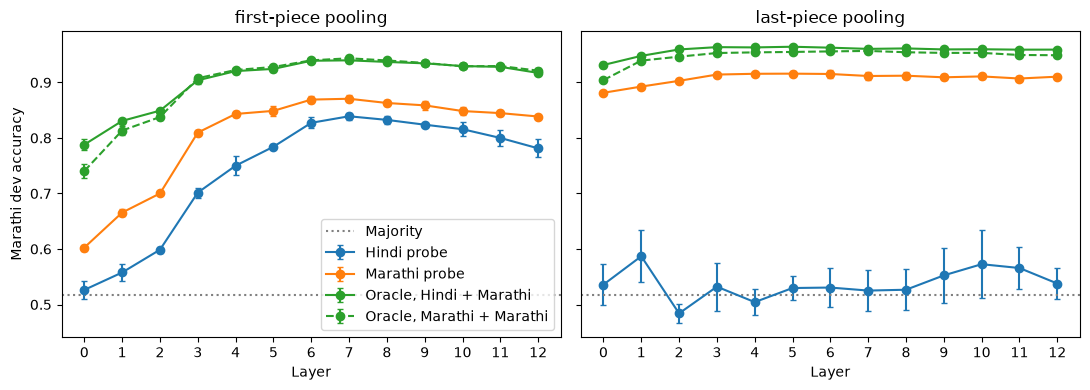

In [3]:
import matplotlib.pyplot as plt

runs = []
for pooling in CONFIG["poolings"]:
    for layer in range(CONFIG["layers"]):
        x_dev, y_dev = load("mr", "dev", layer, pooling)
        for seed in map(str, CONFIG["seeds"]):
            order = samples["mr"][seed]
            hindi_probe = fit(*load("hi", "train", layer, pooling, set(samples["hi"][seed])))
            marathi_probe = fit(*load("mr", "train", layer, pooling, set(order[:n])))
            second_probe = fit(*load("mr", "train", layer, pooling, set(order[n:2 * n])))
            hindi, marathi, second = (probe.predict(x_dev) == y_dev
                                      for probe in (hindi_probe, marathi_probe, second_probe))
            runs.append({
                "pooling": pooling, "layer": layer, "seed": int(seed),
                "hindi": hindi.mean(),
                "marathi": marathi.mean(),
                "disagree": np.mean(hindi != marathi),
                "only_hindi_right": np.mean(hindi & ~marathi),
                "oracle": np.mean(hindi | marathi),
                "cosine": cosine(hindi_probe, marathi_probe),
                "marathi_2": second.mean(),
                "mm_disagree": np.mean(second != marathi),
                "only_marathi_2_right": np.mean(second & ~marathi),
                "mm_oracle": np.mean(second | marathi),
                "mm_cosine": cosine(second_probe, marathi_probe),
            })
        print(f"{pooling} layer {layer} done", flush=True)

tables = {
    "Hindi + Marathi": ["hindi", "marathi", "disagree", "only_hindi_right", "oracle", "cosine"],
    "Marathi + Marathi": ["marathi_2", "marathi", "mm_disagree", "only_marathi_2_right", "mm_oracle", "mm_cosine"],
}
measures = [key for key in runs[0] if key not in ("pooling", "layer", "seed")]
summary = []
for pooling in CONFIG["poolings"]:
    for layer in range(CONFIG["layers"]):
        group = [run for run in runs if run["pooling"] == pooling and run["layer"] == layer]
        summary.append({"pooling": pooling, "layer": layer,
                        **{key: {"mean": np.mean([run[key] for run in group]),
                                 "std": np.std([run[key] for run in group])} for key in measures}})
result = {"split": "mr dev", "majority": majority, "summary": summary, "runs": runs}
(ROOT / "results" / "headroom.json").write_text(json.dumps(result, indent=2) + "\n")

for title, keys in tables.items():
    print(f"\n{title}")
    print(f"{'pooling':8s}{'layer':>6s}" + "".join(f"{key:>22s}" for key in keys))
    for row in summary:
        print(f"{row['pooling']:8s}{row['layer']:6d}" +
              "".join(f"{row[key]['mean']:15.3f} ± {row[key]['std']:.3f}" for key in keys))

figure, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
lines = [("hindi", "Hindi probe", "C0", "-"), ("marathi", "Marathi probe", "C1", "-"),
         ("oracle", "Oracle, Hindi + Marathi", "C2", "-"),
         ("mm_oracle", "Oracle, Marathi + Marathi", "C2", "--")]
for ax, pooling in zip(axes, CONFIG["poolings"]):
    rows = [row for row in summary if row["pooling"] == pooling]
    for key, label, color, style in lines:
        ax.errorbar([row["layer"] for row in rows], [row[key]["mean"] for row in rows],
                    yerr=[row[key]["std"] for row in rows], color=color, linestyle=style,
                    marker="o", capsize=2, label=label)
    ax.axhline(majority, color="grey", linestyle=":", label="Majority")
    ax.set(title=f"{pooling}-piece pooling", xlabel="Layer", xticks=range(CONFIG["layers"]))
axes[0].set_ylabel("Marathi dev accuracy")
axes[0].legend()
figure.tight_layout()
figure.savefig(ROOT / "results" / "headroom.png", dpi=150)
plt.show()